In [1]:
import pandas as pd
import numpy as np

In [10]:
matches = pd.read_csv('matches.csv', index_col=0)
matches.head()

,season,team,opponent,venue,gf,ga,sh,sot,opp_sh,opp_sot,fouls,corners,yellow,red,result
date,,,,,,,,,,,,,,,
2026-08-21,2027,Arsenal,Coventry,Home,3,0,20,6,4,1,10,8,1,0,W
2026-08-31,2027,Arsenal,Aston Villa,Away,1,0,7,2,7,0,6,4,1,0,W
2026-09-06,2027,Arsenal,Chelsea,Home,2,1,16,9,13,5,13,5,2,0,W
2026-09-12,2027,Arsenal,Sunderland,Away,2,0,11,5,12,3,11,2,2,0,W
2026-09-19,2027,Arsenal,Brighton,Away,0,3,11,2,17,5,11,6,1,0,L


In [49]:
matches.tail()

,season,team,opponent,venue,gf,ga,sh,sot,opp_sh,opp_sot,fouls,corners,yellow,red,result
date,,,,,,,,,,,,,,,
2023-04-29,2023,Wolves,Brighton,Away,0,6,10,2,22,8,11,5,1,0,L
2023-05-06,2023,Wolves,Aston Villa,Home,1,0,6,2,16,3,20,5,3,0,W
2023-05-13,2023,Wolves,Man United,Away,0,2,5,0,27,9,9,7,2,0,L
2023-05-20,2023,Wolves,Everton,Home,1,1,13,5,19,4,18,1,5,0,D
2023-05-28,2023,Wolves,Arsenal,Away,0,5,6,0,14,8,11,4,0,0,L


In [12]:
matches['team'].value_counts()

team
Arsenal             157
Aston Villa         157
Bournemouth         157
Brentford           157
Brighton            157
Chelsea             157
Crystal Palace      157
Everton             157
Fulham              157
Liverpool           157
Man City            157
Man United          157
Newcastle           157
Nott'm Forest       157
Tottenham           157
West Ham            152
Wolves              152
Leeds                81
Burnley              76
Leicester            76
Southampton          76
Ipswich              43
Sunderland           43
Luton                38
Sheffield United     38
Coventry              5
Hull                  5
Name: count, dtype: int64

In [9]:
38 * 20 * 4

3040

In [8]:
matches['date'].min()

'2022-08-05'

In [13]:
matches['team'].nunique()

27

#### Teams aggregating the most points

In [16]:
most_points = matches.groupby('team')['result'].value_counts()

In [19]:
most_points_df = pd.DataFrame(most_points)
most_points_df

count
team        result       
Arsenal     W         104
            D          32
            L          21
Aston Villa W          77
            L          47
...                   ...
West Ham    W          46
            D          36
Wolves      L          81
            W          39
            D          32

[80 rows x 1 columns]

In [20]:
most_points_df.head()

count
team        result       
Arsenal     W         104
            D          32
            L          21
Aston Villa W          77
            L          47

In [26]:
most_points_df.columns = [
    "_".join(map(str, col)).strip("_") if isinstance(col, tuple) else col
    for col in most_points_df.columns
]

In [28]:
most_points_df = most_points_df.reset_index()
most_points_df.head()

,team,result,count
0,Arsenal,W,104
1,Arsenal,D,32
2,Arsenal,L,21
3,Aston Villa,W,77
4,Aston Villa,L,47


In [47]:
most_points_df.to_csv('points_by_team.csv')

In [34]:
teams_set = set(most_points_df['team'])
teams_set

{'Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Chelsea',
 'Coventry',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Hull',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Newcastle',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Sunderland',
 'Tottenham',
 'West Ham',
 'Wolves'}

In [43]:
points_map = {'W': 3, 'D': 1, "L": 0}
most_points_df['multiplier'] = most_points_df['result'].map(points_map).fillna(0)
most_points_df['points'] = most_points_df['count'] * most_points_df['multiplier']
most_points_df.head() 

,team,result,count,multiplier,points
0,Arsenal,W,104,3,312
1,Arsenal,D,32,1,32
2,Arsenal,L,21,0,0
3,Aston Villa,W,77,3,231
4,Aston Villa,L,47,0,0


In [44]:
team_points = (
    most_points_df.groupby('team')['points']
    .sum()
    .reset_index()
    .sort_values(by='points', ascending=False)
)

team_points.head()


,team,points
0,Arsenal,344
17,Man City,344
15,Liverpool,302
1,Aston Villa,264
19,Newcastle,254


In [48]:
team_points

,team,points
0,Arsenal,344
17,Man City,344
15,Liverpool,302
1,Aston Villa,264
19,Newcastle,254
18,Man United,253
6,Chelsea,235
4,Brighton,234
3,Brentford,216
10,Fulham,207


In [51]:
pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 2.5 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.3 MB 3.4 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 3.5 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 3.4 MB/s eta 0:00:02
   --------------- ------------------------ 3.7/9.3 MB 3.4 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.3 MB 3.4 MB/s eta 0:00:02
   --------------------- ------------------ 5.0/9.3 MB 3.4 MB/s eta 0:00:02
   ------------------------ --------------- 5.8/9.3 MB 3.4 MB/s eta 0:00:02
   ---------------------------- ----------- 6.6/9.3 MB 3.5 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 3.4 MB/s eta 0:00:01
   --------------------------

findfont: Failed to find font weight black for DejaVu Sans, now using 700.
findfont: Failed to find font weight black for DejaVu Sans, now using 700.


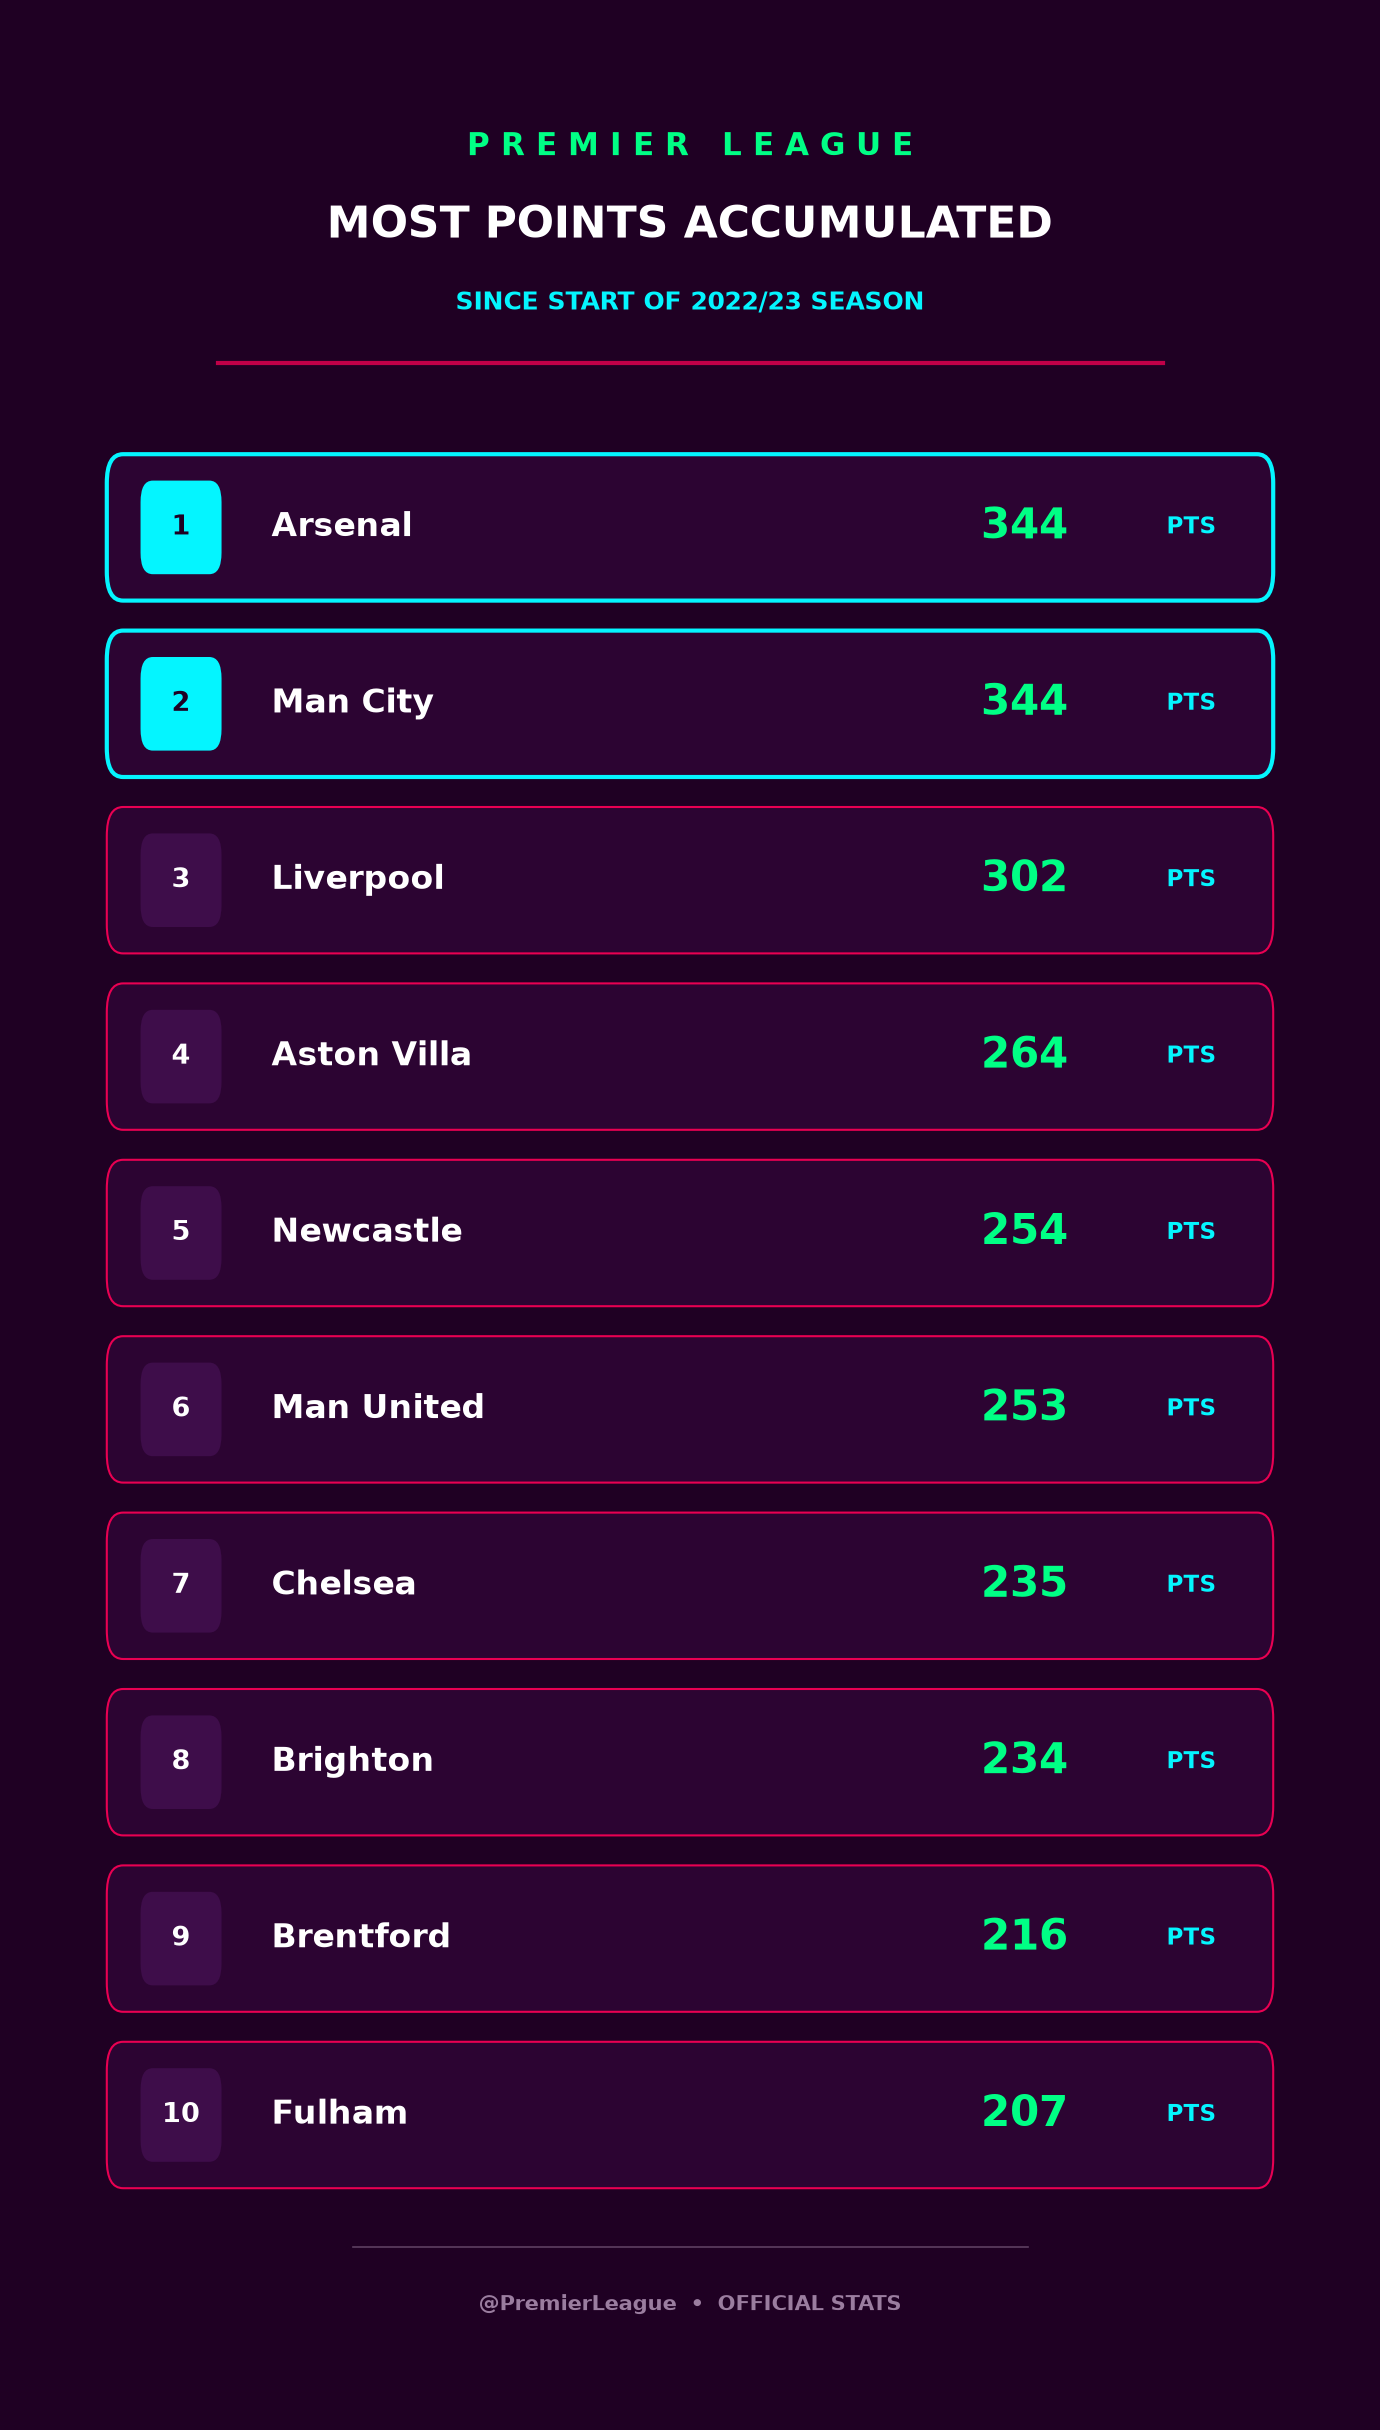

In [54]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Data for top 10 teams
teams_data = [
    (1, "Arsenal", 344),
    (2, "Man City", 344),
    (3, "Liverpool", 302),
    (4, "Aston Villa", 264),
    (5, "Newcastle", 254),
    (6, "Man United", 253),
    (7, "Chelsea", 235),
    (8, "Brighton", 234),
    (9, "Brentford", 216),
    (10, "Fulham", 207),
]

# 9:16 Instagram vertical aspect ratio (1080 x 1920 equivalent)
fig, ax = plt.subplots(figsize=(9, 16), dpi=150)
bg_color = "#1f0023"      # Premier League plum
card_color = "#2c0432"    # Card fill
card_border = "#e90052"   # PL magenta
neon_cyan = "#04f5ff"     # Glow cyan
neon_green = "#00ff85"    # PL signature green
white = "#ffffff"
text_muted = "#9a7d9f"

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Header Section (spaced strings used instead of letterspacing)
ax.text(50, 94.5, "P R E M I E R   L E A G U E", fontsize=15, weight="bold", color=neon_green, ha="center", va="center")
ax.text(50, 91.2, "MOST POINTS ACCUMULATED", fontsize=21, weight="black", color=white, ha="center", va="center")
ax.text(50, 88.0, "SINCE START OF 2022/23 SEASON", fontsize=12, weight="bold", color=neon_cyan, ha="center", va="center")

# Divider line
ax.plot([15, 85], [85.5, 85.5], color=card_border, lw=2, alpha=0.8)

# Vertical Leaderboard Cards
row_y_start = 81.5
row_gap = 7.35
card_height = 5.7
card_width = 86
card_x = 7

for i, (rank, team, pts) in enumerate(teams_data):
    y = row_y_start - (i * row_gap)
    
    # Leader highlight for joint top spots
    if rank <= 2:
        border_col = neon_cyan
        lw = 2.0
        rank_bg = neon_cyan
        rank_text_col = bg_color
    else:
        border_col = card_border
        lw = 1.0
        rank_bg = "#3e0d4a"
        rank_text_col = white

    # Outer pill card
    rect = patches.FancyBboxPatch(
        (card_x, y - card_height),
        card_width,
        card_height,
        boxstyle="round,pad=0.2,rounding_size=1.2",
        linewidth=lw,
        edgecolor=border_col,
        facecolor=card_color,
    )
    ax.add_patch(rect)

    # Rank badge
    badge = patches.FancyBboxPatch(
        (card_x + 2.5, y - card_height + 1.1),
        5.6,
        3.5,
        boxstyle="round,pad=0.2,rounding_size=0.9",
        linewidth=0,
        facecolor=rank_bg,
    )
    ax.add_patch(badge)
    ax.text(card_x + 5.3, y - card_height / 2, f"{rank}", fontsize=13, weight="bold", color=rank_text_col, ha="center", va="center")

    # Team name
    ax.text(card_x + 12.0, y - card_height / 2, team, fontsize=16, weight="bold", color=white, ha="left", va="center")

    # Points value and PTS suffix
    ax.text(card_x + card_width - 15.0, y - card_height / 2, f"{pts}", fontsize=20, weight="black", color=neon_green, ha="right", va="center")
    ax.text(card_x + card_width - 4.0, y - card_height / 2, "PTS", fontsize=11, weight="bold", color=neon_cyan, ha="right", va="center")

# Footer
ax.plot([25, 75], [7.0, 7.0], color=text_muted, lw=0.8, alpha=0.5)
ax.text(50, 4.6, "@PremierLeague  •  OFFICIAL STATS", fontsize=10, weight="bold", color=text_muted, ha="center", va="center")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig("premier_league_vertical_story.png", dpi=300, facecolor=bg_color)
plt.show()

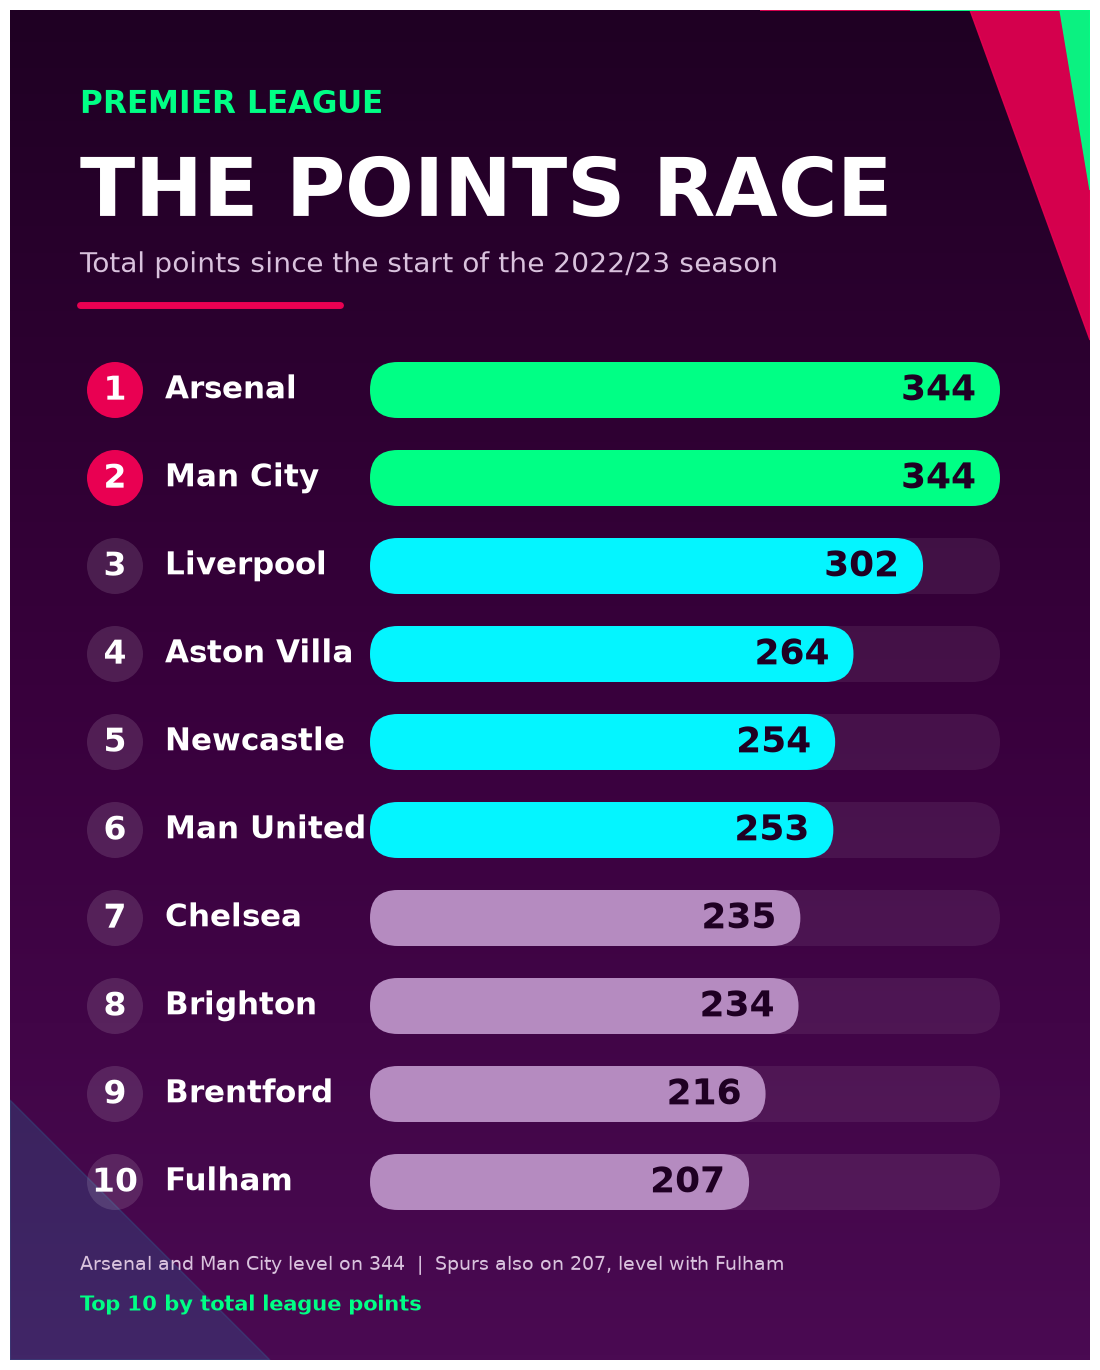

In [53]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, FancyBboxPatch

# ---------------------------------------------------------------
# Data: uses your existing `team_points` DataFrame (columns: team, points).
# If running this as a standalone script, uncomment the block below.
# ---------------------------------------------------------------
# team_points = pd.DataFrame({
#     "team": ["Arsenal", "Man City", "Liverpool", "Aston Villa", "Newcastle",
#              "Man United", "Chelsea", "Brighton", "Brentford", "Fulham", "Tottenham"],
#     "points": [344, 344, 302, 264, 254, 253, 235, 234, 216, 207, 207],
# })

top10 = (team_points.sort_values("points", ascending=False, kind="stable")
                    .head(10)[["team", "points"]]
                    .values.tolist())

# Premier League palette
PURPLE, DEEP = "#38003c", "#1f0023"
GREEN, MAG, CYAN = "#00ff85", "#e90052", "#04f5ff"
WHITE, SOFT, MUTED = "#ffffff", "#b58bc0", "#d9c2dd"

W, H = 1080, 1350  # Instagram 4:5 portrait
fig = plt.figure(figsize=(W / 100, H / 100), dpi=100)
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, W); ax.set_ylim(0, H); ax.axis("off")

# Background gradient
bg = LinearSegmentedColormap.from_list("bg", [DEEP, PURPLE, "#4a0a52"])
ax.imshow(np.linspace(0, 1, 256).reshape(-1, 1), extent=[0, W, 0, H],
          aspect="auto", cmap=bg, origin="upper", zorder=0)

# Decorative corner accents
ax.fill([W - 330, W, W, W - 120], [H, H, H - 330, H], color=MAG, alpha=0.9, zorder=1)
ax.fill([W - 180, W, W, W - 30], [H, H, H - 180, H], color=GREEN, alpha=0.95, zorder=1)
ax.fill([0, 260, 0], [0, 0, 260], color=CYAN, alpha=0.12, zorder=1)

# Header
ax.text(70, H - 95, "PREMIER LEAGUE", color=GREEN, fontsize=22, fontweight="bold", va="center", zorder=5)
ax.text(70, H - 185, "THE POINTS RACE", color=WHITE, fontsize=58, fontweight="bold", va="center", zorder=5)
ax.text(70, H - 255, "Total points since the start of the 2022/23 season",
        color=MUTED, fontsize=20, va="center", zorder=5)
ax.plot([70, 330], [H - 295, H - 295], color=MAG, lw=5, solid_capstyle="round", zorder=5)

# Bars
top, row, x0, maxw = H - 380, 88, 360, 630
mx = max(p for _, p in top10)

for i, (team, pts) in enumerate(top10):
    y = top - i * row
    w = maxw * pts / mx
    lead = i < 2
    bar_col = GREEN if lead else (CYAN if i < 6 else SOFT)

    # track + bar
    ax.add_patch(FancyBboxPatch((x0, y - 28), maxw, 56, boxstyle="round,pad=0,rounding_size=28",
                                fc=WHITE, alpha=0.07, ec="none", zorder=2))
    ax.add_patch(FancyBboxPatch((x0, y - 28), w, 56, boxstyle="round,pad=0,rounding_size=28",
                                fc=bar_col, ec="none", zorder=3))
    # rank badge
    ax.add_patch(Circle((105, y), 28, fc=MAG if lead else WHITE,
                        alpha=1 if lead else 0.12, ec="none", zorder=3))
    ax.text(105, y - 1, str(i + 1), color=WHITE, fontsize=24, fontweight="bold",
            ha="center", va="center", zorder=5)
    # team + points
    ax.text(155, y, team, color=WHITE, fontsize=22, fontweight="bold", va="center", zorder=5)
    ax.text(x0 + w - 24, y - 1, str(pts), color=DEEP, fontsize=26, fontweight="bold",
            ha="right", va="center", zorder=5)

# Footer
ax.text(70, 95, "Arsenal and Man City level on 344  |  Spurs also on 207, level with Fulham",
        color=MUTED, fontsize=14, va="center", zorder=5)
ax.text(70, 55, "Top 10 by total league points", color=GREEN, fontsize=15,
        fontweight="bold", va="center", zorder=5)

fig.savefig("premier_league_points_top10.png", dpi=100, facecolor=PURPLE)
plt.show()

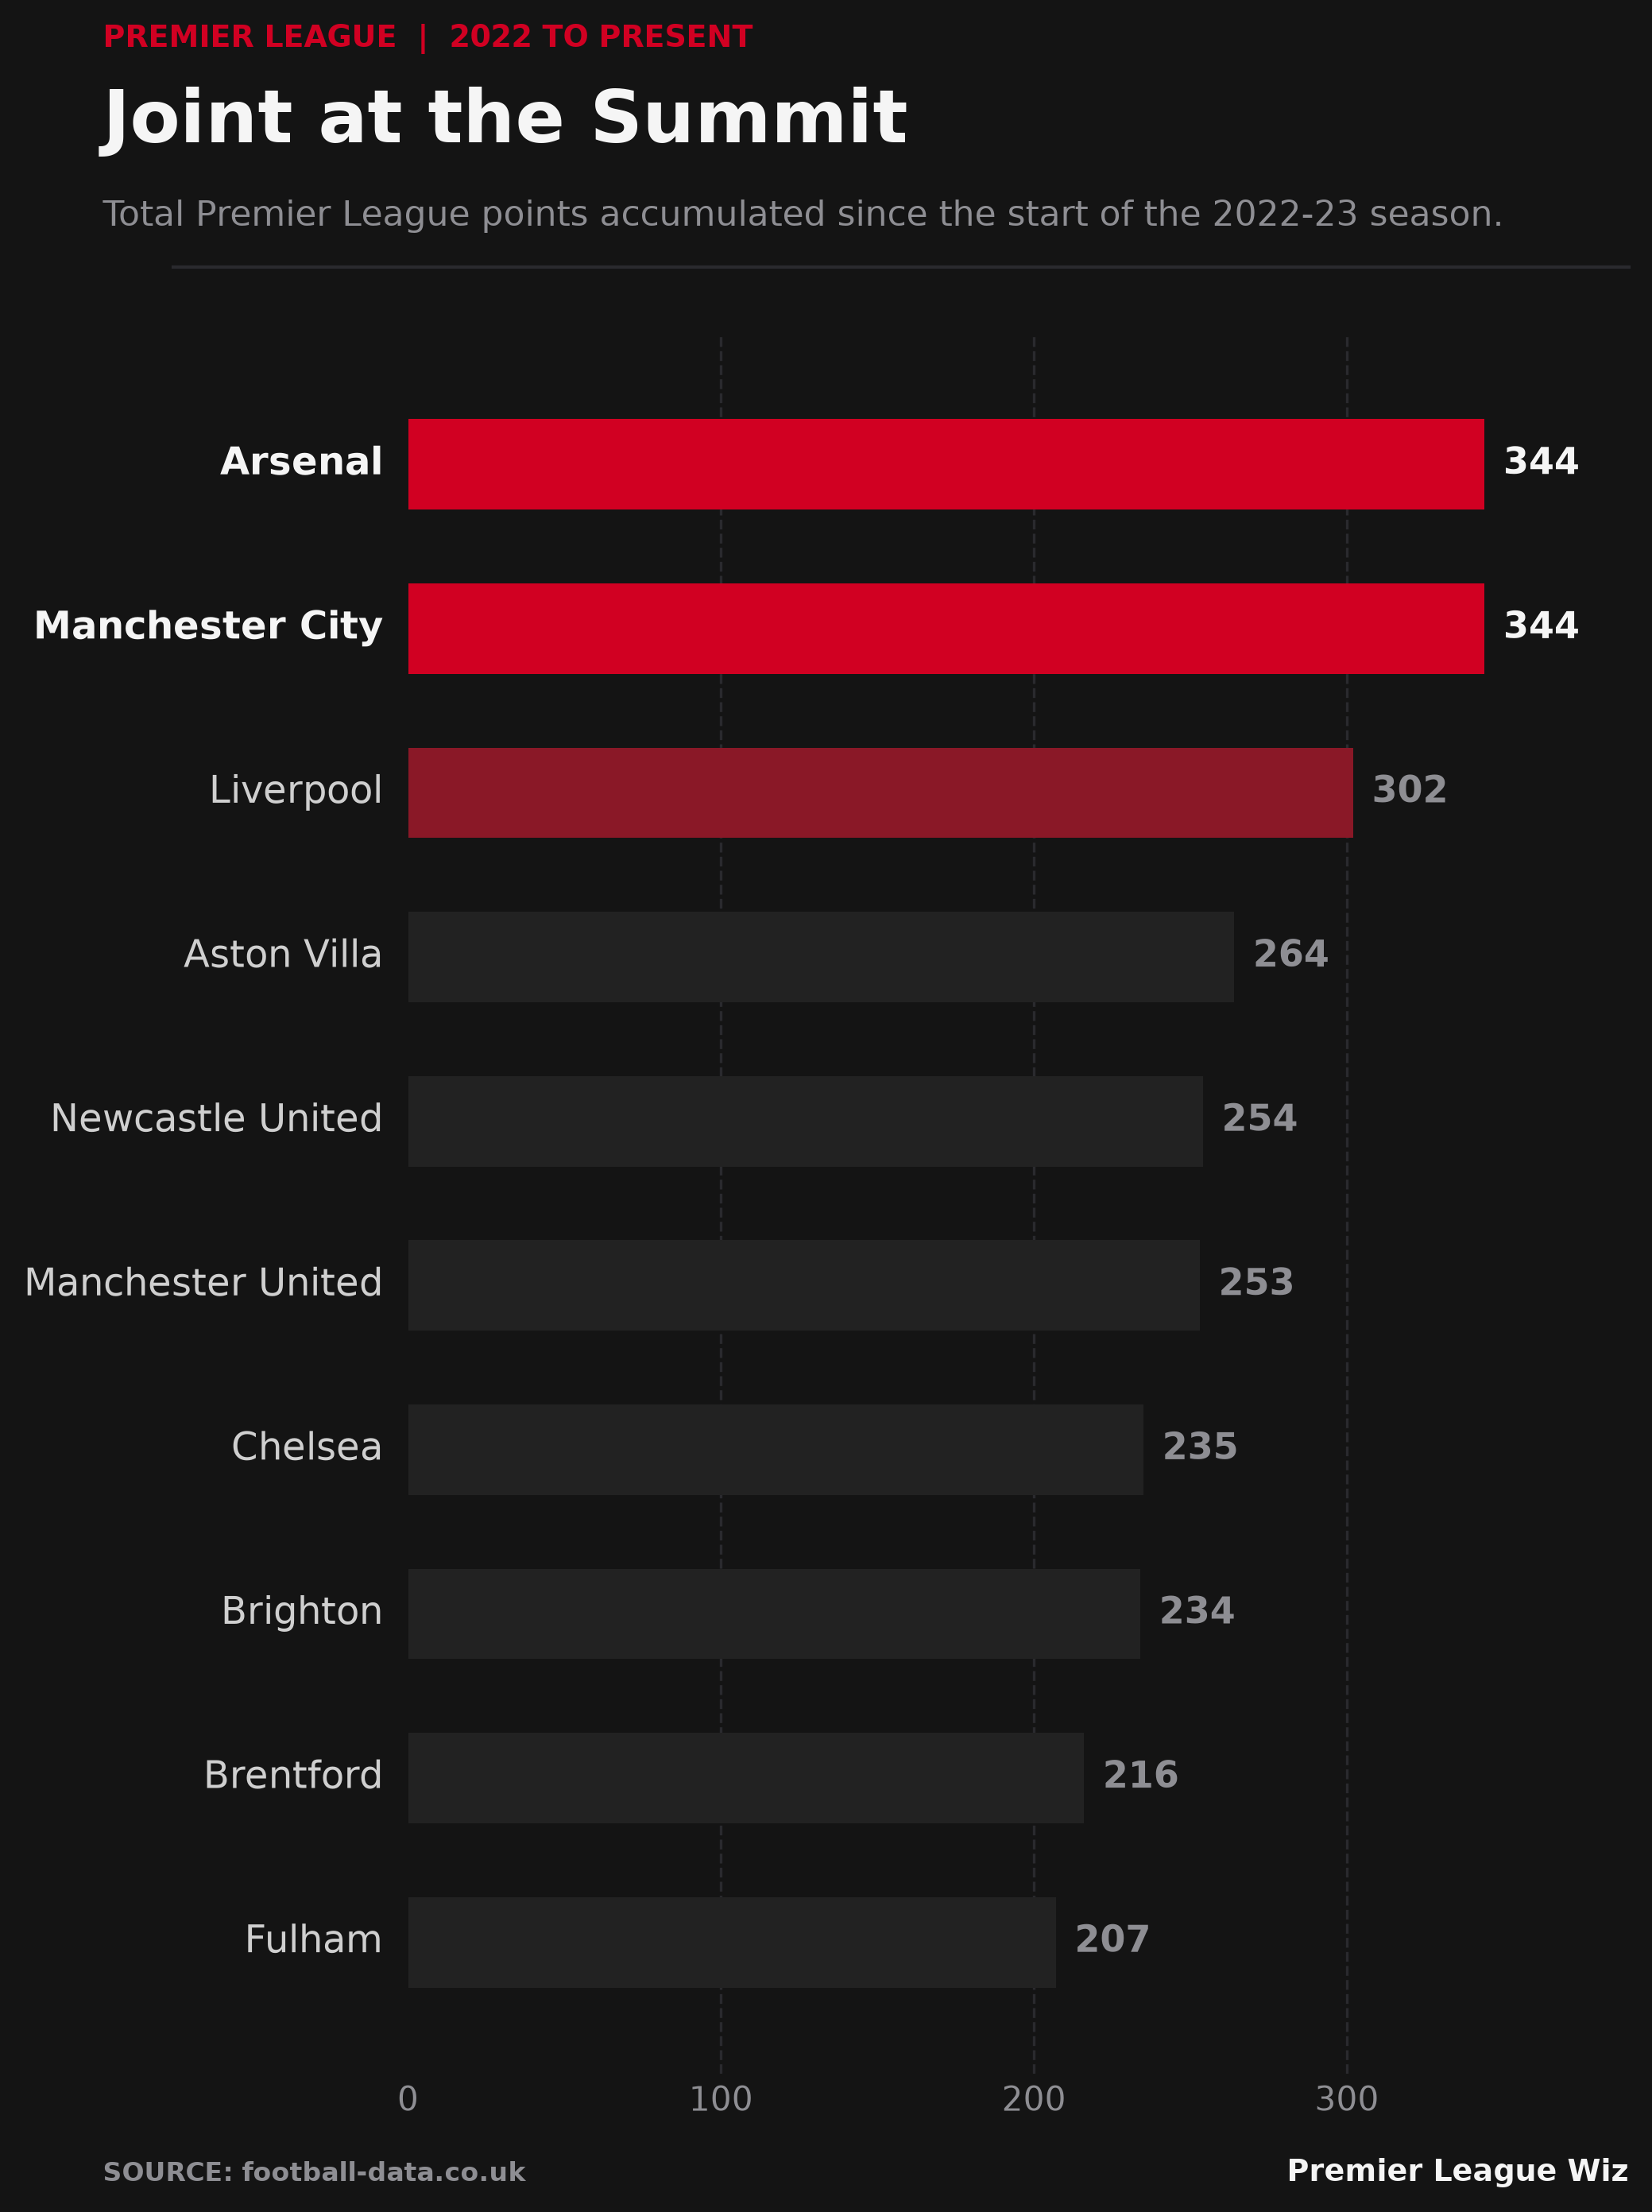

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# Data
data = [
    ("Arsenal", 344),
    ("Manchester City", 344),
    ("Liverpool", 302),
    ("Aston Villa", 264),
    ("Newcastle United", 254),
    ("Manchester United", 253),
    ("Chelsea", 235),
    ("Brighton", 234),
    ("Brentford", 216),
    ("Fulham", 207),
]

# Invert order so rank #1 sits at the top
teams, points = zip(*reversed(data))
y_positions = np.arange(len(teams))

# 4:5 Aspect Ratio (1080 x 1350 equivalent) for Instagram Feed
fig, ax = plt.subplots(figsize=(8, 10), dpi=300)

# The Athletic palette
bg_color = "#141414"        # Editorial matte charcoal
bar_muted = "#222222"       # Inactive baseline bars
bar_highlight = "#D10022"   # Athletic signature red
text_primary = "#F5F5F5"
text_secondary = "#8E8E93"
grid_color = "#2A2A2E"

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)

# Subtle vertical gridlines
for x_val in range(100, 401, 100):
    ax.axvline(x=x_val, color=grid_color, linestyle="--", linewidth=0.8, zorder=1)

# Selective spotlight coloring (Focus on the title race leaders)
bar_colors = []
for team in teams:
    if team in ["Arsenal", "Manchester City"]:
        bar_colors.append(bar_highlight)
    elif team == "Liverpool":
        bar_colors.append("#8A1827")
    else:
        bar_colors.append(bar_muted)

# Render horizontal bars
bars = ax.barh(
    y_positions, 
    points, 
    color=bar_colors, 
    edgecolor="none", 
    height=0.55, 
    zorder=2
)

# Team names (left-aligned along y-axis) and values (at bar tips)
for i, (team, pts) in enumerate(zip(teams, points)):
    is_top = team in ["Arsenal", "Manchester City"]
    ax.text(
        -8, 
        i, 
        team, 
        va="center", 
        ha="right", 
        fontsize=11.5, 
        fontweight="bold" if is_top else "normal", 
        color=text_primary if is_top else "#CFCFCF"
    )
    ax.text(
        pts + 6, 
        i, 
        str(pts), 
        va="center", 
        ha="left", 
        fontsize=11, 
        fontweight="bold", 
        color=text_primary if is_top else text_secondary
    )

# Clean borders
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_yticks([])
ax.set_xlim(0, 390)
ax.set_ylim(-0.8, len(teams) - 0.2)

# X-axis ticks
ax.set_xticks([0, 100, 200, 300])
ax.set_xticklabels(["0", "100", "200", "300"], fontsize=10, color=text_secondary, fontweight="medium")
ax.tick_params(axis="x", colors=text_secondary, length=0)

# Editorial Typography Structure
# 1. Topic Kicker
fig.text(0.12, 0.94, "PREMIER LEAGUE  |  2022 TO PRESENT", fontsize=9, fontweight="bold", color=bar_highlight, ha="left")
# 2. Headline
fig.text(0.12, 0.90, "Joint at the Summit", fontsize=22, fontweight="heavy", color=text_primary, ha="left")
# 3. Explanatory Deck
fig.text(0.12, 0.865, "Total Premier League points accumulated since the start of the 2022-23 season.", 
         fontsize=10.5, color=text_secondary, ha="left")

# Section separator
ax.plot([-75, 390], [10.2, 10.2], color=grid_color, lw=1, clip_on=False)

# Footer credits
fig.text(0.12, 0.045, "SOURCE: football-data.co.uk", fontsize=8, color=text_secondary, ha="left", fontweight="semibold")
fig.text(0.92, 0.045, "Premier League Wiz", fontsize=9, color=text_primary, ha="right", fontweight="black")

plt.subplots_adjust(top=0.82, bottom=0.09, left=0.28, right=0.92)
plt.savefig("the_athletic_pl_points.png", dpi=300, facecolor=bg_color)
plt.show()

findfont: Failed to find font weight heavy for DejaVu Sans, now using 700.
findfont: Failed to find font weight heavy for DejaVu Sans, now using 700.


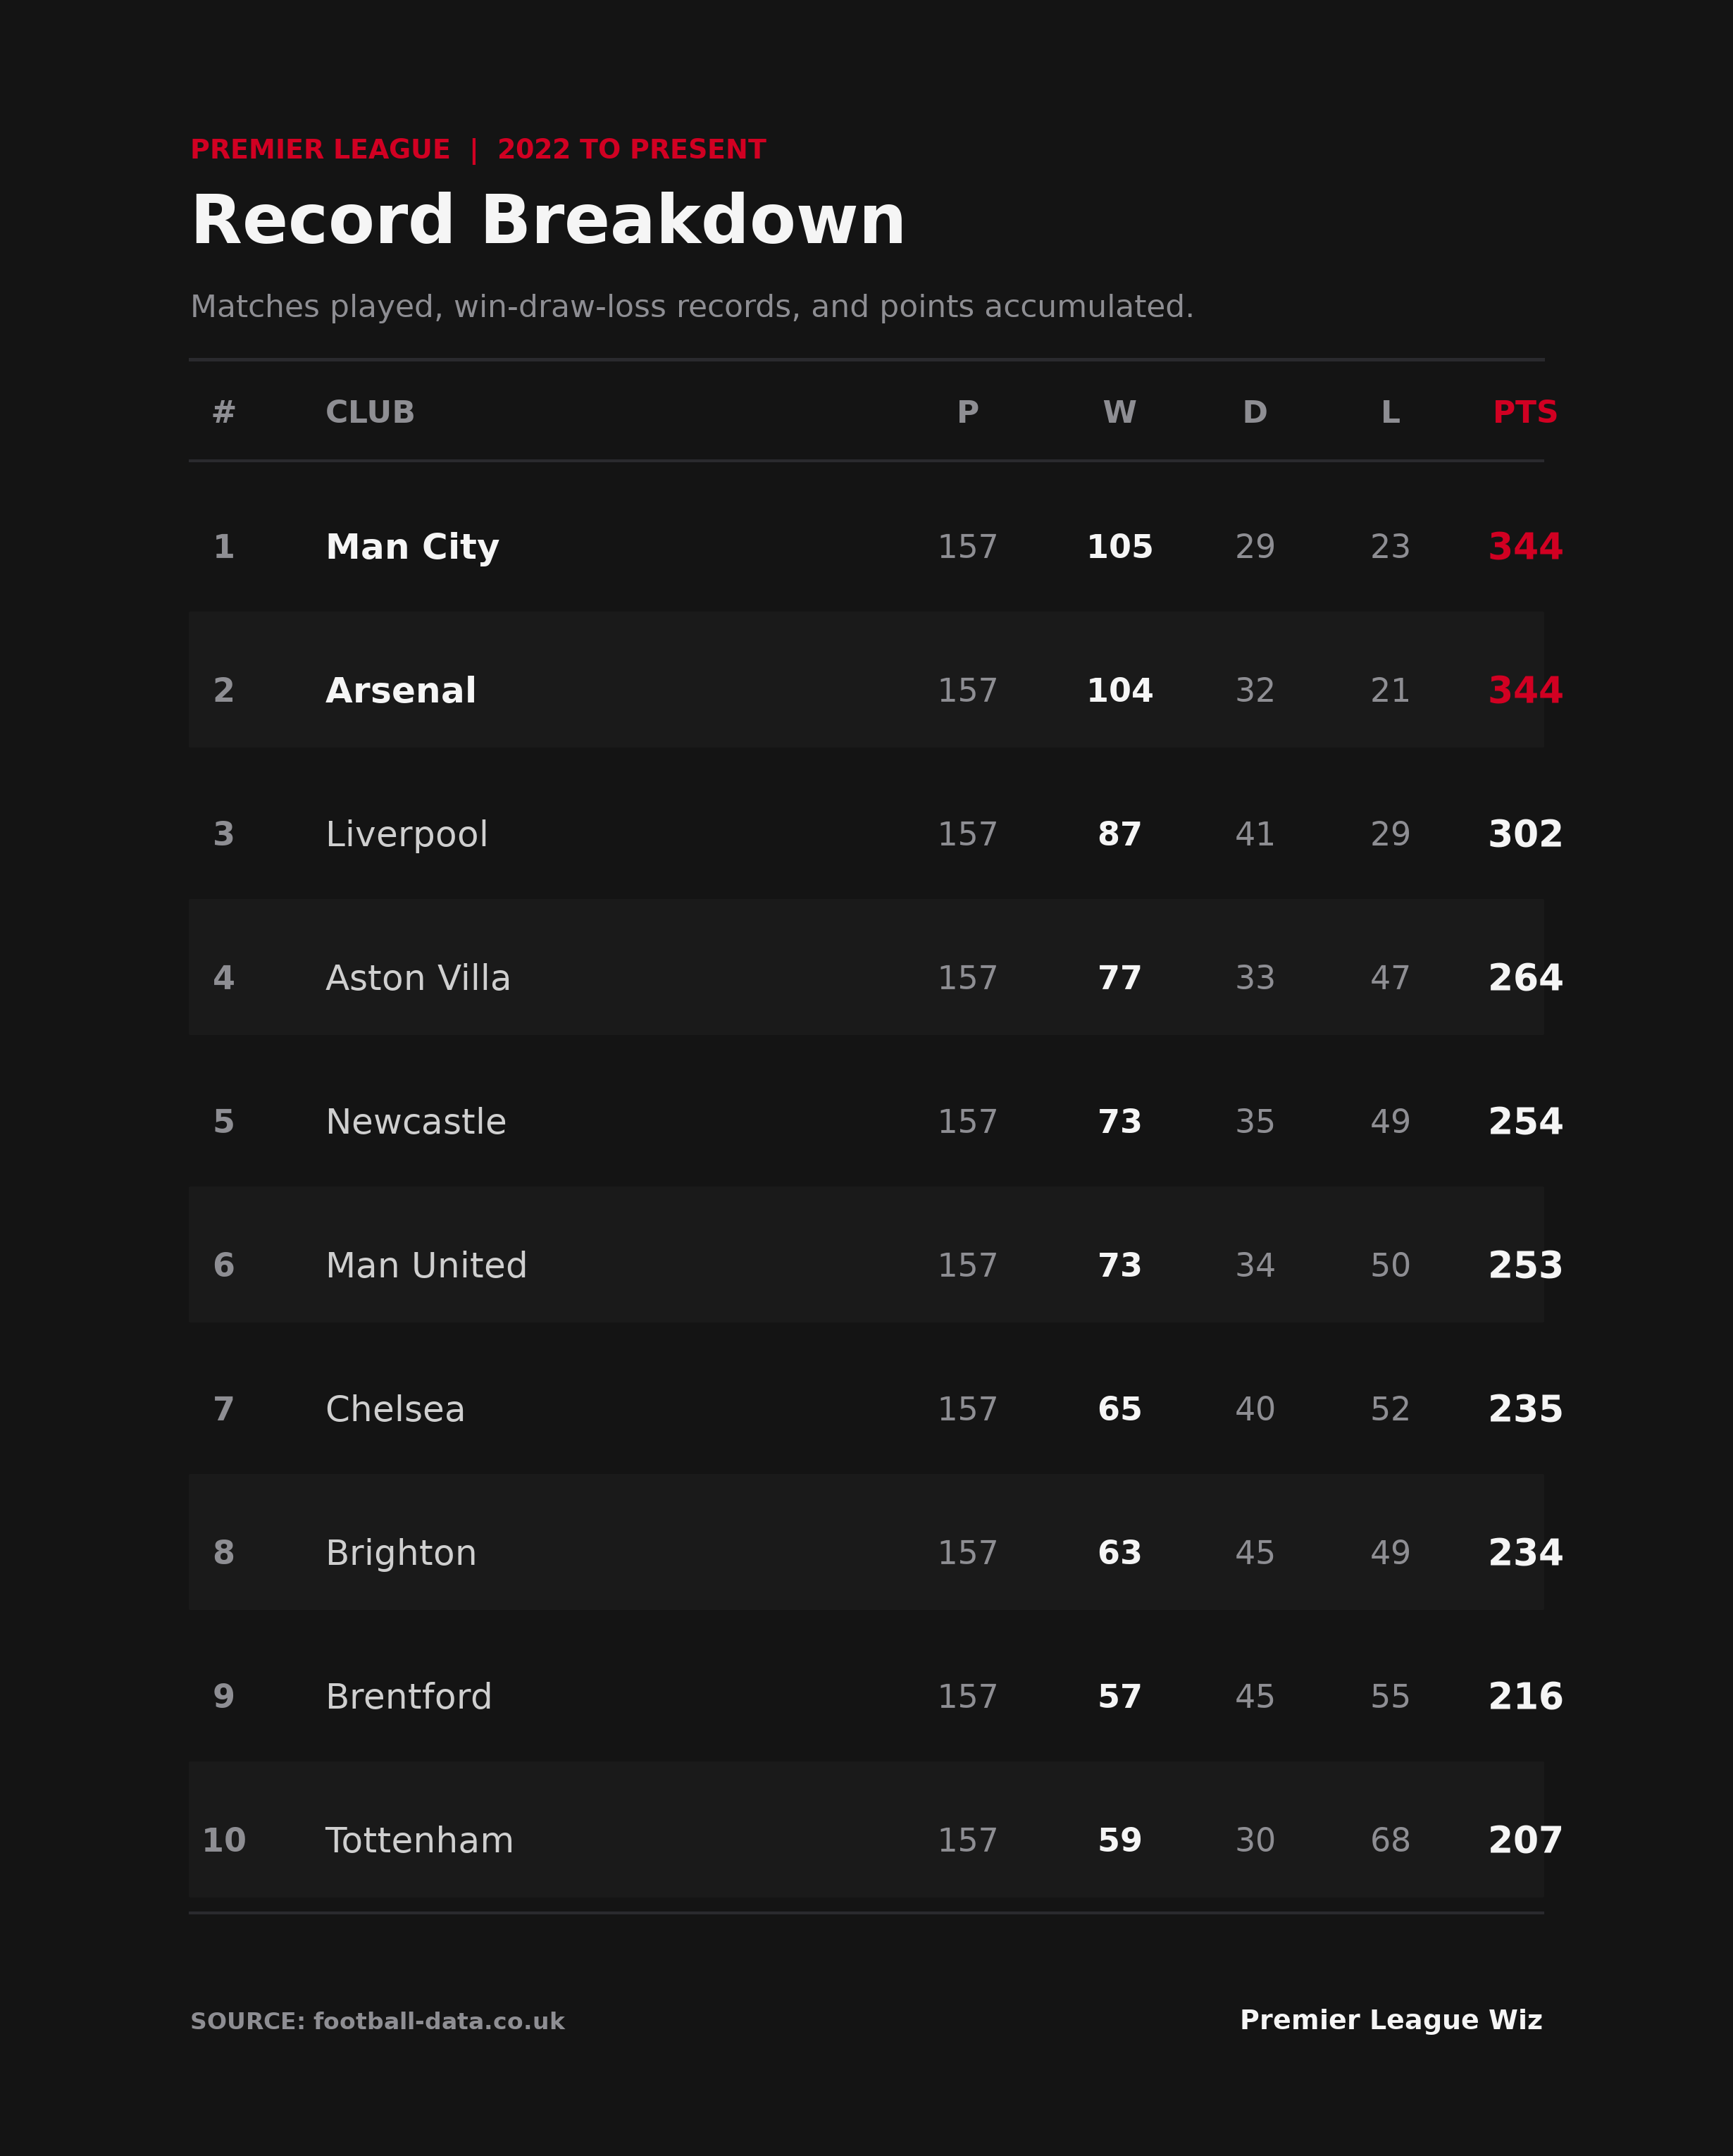

In [59]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Transform your long DataFrame into a tabular standings format
# (Assuming your dataframe is named `most_points_df`)
table_df = most_points_df.pivot_table(
    index='team', columns='result', values='count', fill_value=0
)

# Ensure W, D, L columns exist
for col in ['W', 'D', 'L']:
    if col not in table_df.columns:
        table_df[col] = 0

# Compute matches played (P) and total points (PTS)
table_df['P'] = table_df['W'] + table_df['D'] + table_df['L']
table_df['PTS'] = (table_df['W'] * 3) + (table_df['D'] * 1)

# Sort by points (then wins as tiebreaker) and slice top 10
table_df = (
    table_df[['P', 'W', 'D', 'L', 'PTS']]
    .sort_values(by=['PTS', 'W'], ascending=[False, False])
    .reset_index()
    .head(10)
)
table_df['Rank'] = range(1, len(table_df) + 1)

# 2. Setup 4:5 vertical canvas (The Athletic editorial theme)
fig, ax = plt.subplots(figsize=(8, 10), dpi=300)
bg_color = "#141414"        # Matte charcoal
border_col = "#2A2A2E"      # Subtle divider line
accent_red = "#D10022"      # Athletic signature crimson
text_white = "#F5F5F5"
text_muted = "#8E8E93"
zebra_row = "#1A1A1A"       # Alternating subtle row band

fig.patch.set_facecolor(bg_color)
ax.set_facecolor(bg_color)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# 3. Typography & Header Deck
fig.text(0.10, 0.935, "PREMIER LEAGUE  |  2022 TO PRESENT", fontsize=9, fontweight="bold", color=accent_red, ha="left")
fig.text(0.10, 0.895, "Record Breakdown", fontsize=23, fontweight="heavy", color=text_white, ha="left")
fig.text(0.10, 0.860, "Matches played, win-draw-loss records, and points accumulated.", fontsize=10.5, color=text_muted, ha="left")

# Section separator
ax.plot([10, 90], [84, 84], color=border_col, lw=1.2)

# Column X-coordinates
col_x = {'Rank': 12, 'Team': 18, 'P': 56, 'W': 65, 'D': 73, 'L': 81, 'PTS': 89}

# Table Column Headers
header_y = 81.0
ax.text(col_x['Rank'], header_y, "#", fontsize=10.5, color=text_muted, weight="bold", ha="center")
ax.text(col_x['Team'], header_y, "CLUB", fontsize=10.5, color=text_muted, weight="bold", ha="left")
ax.text(col_x['P'], header_y, "P", fontsize=10.5, color=text_muted, weight="bold", ha="center")
ax.text(col_x['W'], header_y, "W", fontsize=10.5, color=text_muted, weight="bold", ha="center")
ax.text(col_x['D'], header_y, "D", fontsize=10.5, color=text_muted, weight="bold", ha="center")
ax.text(col_x['L'], header_y, "L", fontsize=10.5, color=text_muted, weight="bold", ha="center")
ax.text(col_x['PTS'], header_y, "PTS", fontsize=10.5, color=accent_red, weight="bold", ha="center")

ax.plot([10, 90], [79.2, 79.2], color=border_col, lw=1)

# 4. Render Table Rows
start_y = 75.0
row_step = 6.8

for idx, row in table_df.iterrows():
    curr_y = start_y - (idx * row_step)

    # Alternating row background for clean scanning
    if idx % 2 == 1:
        ax.fill_between([10, 90], curr_y - 2.5, curr_y + 3.8, color=zebra_row, zorder=0)

    # Emphasize title leaders
    is_leader = row['Rank'] in [1, 2]
    team_color = text_white if is_leader else "#CFCFCF"
    font_wt = "bold" if is_leader else "normal"
    pts_color = accent_red if is_leader else text_white

    # Data cells
    ax.text(col_x['Rank'], curr_y, str(row['Rank']), fontsize=11, color=text_muted, weight="bold", ha="center", va="center")
    ax.text(col_x['Team'], curr_y, row['team'], fontsize=12, color=team_color, weight=font_wt, ha="left", va="center")
    ax.text(col_x['P'], curr_y, str(int(row['P'])), fontsize=11, color=text_muted, ha="center", va="center")
    ax.text(col_x['W'], curr_y, str(int(row['W'])), fontsize=11, color=text_white, weight="bold", ha="center", va="center")
    ax.text(col_x['D'], curr_y, str(int(row['D'])), fontsize=11, color=text_muted, ha="center", va="center")
    ax.text(col_x['L'], curr_y, str(int(row['L'])), fontsize=11, color=text_muted, ha="center", va="center")
    ax.text(col_x['PTS'], curr_y, str(int(row['PTS'])), fontsize=12.5, color=pts_color, weight="heavy", ha="center", va="center")

# 5. Footer credits
ax.plot([10, 90], [10.5, 10.5], color=border_col, lw=1)
fig.text(0.10, 0.05, "SOURCE: football-data.co.uk", fontsize=8, color=text_muted, ha="left", fontweight="semibold")
fig.text(0.90, 0.05, "Premier League Wiz", fontsize=9, color=text_white, ha="right", fontweight="black")

plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.savefig("the_athletic_standings_table.png", dpi=300, facecolor=bg_color)
plt.show()